# Manufacturing Downtime — EDA

Run the cells in order. Put `manufacturing_filled.csv` beside this notebook. This EDA uses the filled dataset.


## Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Read the cleaned CSV

In [3]:
df = pd.read_csv('manufacturing_cleaned.csv')


In [3]:
df.head()


,record_id,machine_id,production_line,batch_id,shift,product_type,ambient_temperature,humidity,air_pressure,ambient_vibration,motor_temperature,spindle_speed,motor_current,torque,vibration,acoustic_level,bearing_temperature,process_temperature,hydraulic_pressure,flow_rate,coolant_temperature,material_feed_rate,feed_pressure,cycle_time,throughput_rate,production_volume,machine_utilization,resource_utilization,operator_load,power_consumption,energy_per_unit,defect_rate,quality_score,first_pass_yield,fault_event_count,downtime_minutes,maintenance_frequency,production_cost_per_unit,resource_efficiency,production_efficiency,energy_saving_pct,downtime_reduction_pct,cost_reduction_pct,benefit_score,operation_mode
0,1,M07,Line_A,B0343,Morning,Product_C,24.657935,69.272037,102.335679,0.366190,52.965526,3076.599086,24.551220,47.098043,0.999885,74.644949,72.154406,72.695817,147.135807,69.302627,22.568324,94.063988,82.121635,34.807160,113.734757,125.270994,78.890534,92.707915,56.732792,20.156618,15.912526,2.755694,91.890753,94.702719,2,25.081059,2.172029,8.028928,99.0,99.0,9.364688,49.353148,26.199425,68.260235,High_Throughput
1,2,M20,Line_E,B0593,Afternoon,Product_D,15.953337,59.927354,100.055317,0.472410,48.115477,3145.358704,25.715030,61.296107,1.302627,77.116641,67.374927,67.697289,169.504064,72.208857,20.046634,87.692762,74.184634,28.097116,121.214801,104.791681,70.963414,84.846367,57.412391,20.978039,19.945721,3.002871,92.526603,93.933012,2,20.400191,2.576074,8.537013,99.0,99.0,3.129223,56.434784,30.016525,68.491891,High_Throughput
2,3,M15,Line_E,B0205,Afternoon,Product_C,21.761215,44.487079,102.794636,0.478138,50.351004,2525.512002,27.553259,58.421784,0.836037,70.850881,68.529856,67.481255,151.492770,61.199958,22.084423,80.527624,82.117430,31.877468,103.171201,112.119319,67.045573,88.806869,66.409865,18.877508,17.124998,4.197931,88.203995,91.559242,0,11.608597,2.357031,7.372440,99.0,99.0,6.433856,61.539859,33.412663,68.837230,Balanced_Production
3,4,M11,Line_B,B0993,Morning,Product_A,21.973528,59.022870,98.258859,0.417760,55.413848,3475.501288,27.879476,55.865708,1.514329,74.752200,68.138096,74.293083,164.873692,75.000000,16.727346,67.991498,77.704386,35.333958,121.551425,104.885720,66.658527,87.535560,63.339143,22.535570,20.000000,3.720499,88.981219,93.493815,3,25.542778,2.840125,8.622625,99.0,99.0,3.284783,43.948708,34.699694,67.074754,Balanced_Production
4,5,M08,Line_E,B0961,Night,Product_C,20.595578,54.665654,99.217605,0.283555,48.655944,1968.506912,17.538344,49.317446,1.321812,70.217883,68.736586,78.479911,167.036023,58.739215,19.494110,60.298653,77.179275,31.696253,99.470765,100.686418,73.665866,87.913759,59.663648,16.261478,15.823976,3.202349,89.601794,94.328069,3,19.759181,3.410520,7.521289,99.0,99.0,12.958237,52.025084,31.553079,69.084109,Precision_Quality


In [4]:
df.shape


(15000, 45)

## Check missing values


In [5]:
df.isna().sum().sum()


np.int64(0)

## Review numeric values

In [6]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
record_id,15000.0,7500.500000,4330.271354,1.000000,3750.750000,7500.500000,11250.250000,15000.000000
ambient_temperature,15000.0,24.520192,3.175165,15.000000,22.422765,24.520192,26.606495,35.000000
humidity,15000.0,55.002418,10.783910,25.000000,47.789843,55.002418,62.274981,85.000000
air_pressure,15000.0,101.297772,2.046552,96.000000,99.934954,101.297772,102.686545,106.000000
ambient_vibration,15000.0,0.348625,0.119128,0.050000,0.268181,0.349165,0.428356,0.800000
motor_temperature,15000.0,55.181107,4.975569,35.724116,51.869493,55.181107,58.436581,74.289639
spindle_speed,15000.0,2850.524255,418.573700,1500.000000,2569.528199,2850.524255,3127.720061,4000.000000
motor_current,15000.0,24.551220,2.754282,13.720123,22.710528,24.551220,26.417245,35.000000
torque,15000.0,53.090018,5.058990,32.059558,49.732008,53.090018,56.378180,72.608160
vibration,15000.0,1.288602,0.264961,0.238365,1.114975,1.288602,1.465968,2.264449


## Review downtime


In [7]:
df['downtime_minutes'].describe()


,downtime_minutes
count,15000.000000
mean,21.206501
std,6.734687
min,0.000000
25%,16.577125
50%,20.838395
75%,25.563824
max,52.418677


## Downtime distribution
Each bar shows how many records fall in a range of downtime values.

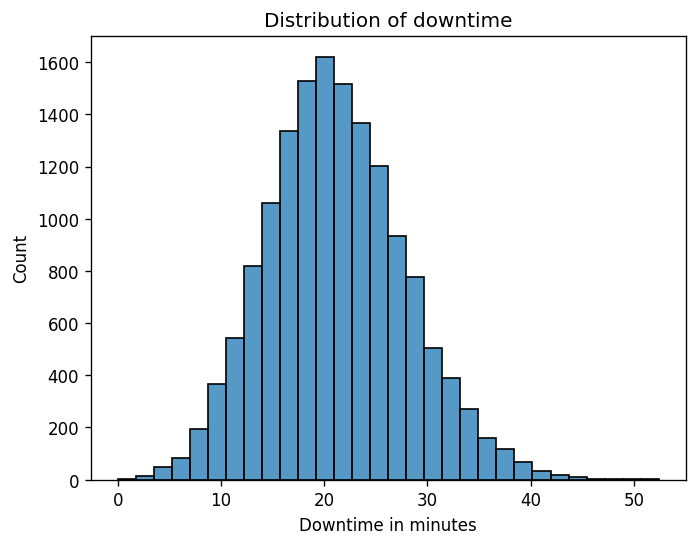

In [8]:
sns.histplot(data=df, x='downtime_minutes', bins=30)
plt.title('Distribution of downtime')
plt.xlabel('Downtime in minutes')
plt.show()


## Check unusual downtime values
Dots beyond the whiskers are unusual observations, not automatically errors.

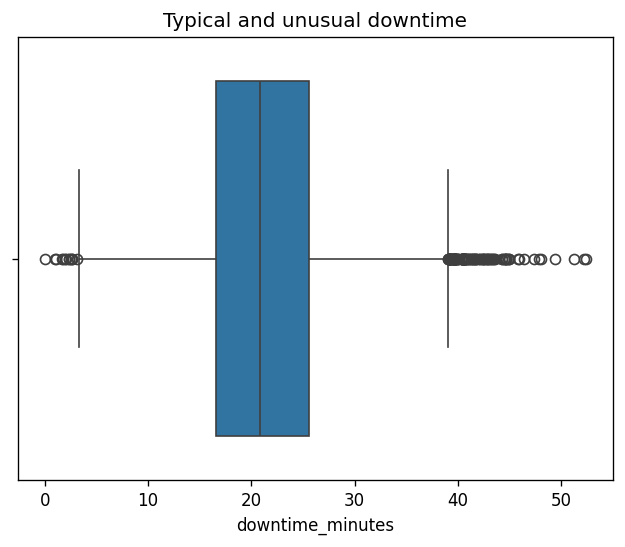

In [9]:
sns.boxplot(data=df, x='downtime_minutes')
plt.title('Typical and unusual downtime')
plt.show()


## Downtime by operating mode
Compare count, mean and median. Different averages do not prove that operating mode causes downtime.

In [10]:
df.groupby('operation_mode')['downtime_minutes'].agg(['count', 'mean', 'median'])


,count,mean,median
operation_mode,,,
Balanced_Production,5250,21.913700,21.693180
Energy_Efficient,3750,26.861212,26.476009
High_Throughput,3000,15.480737,15.345929
Precision_Quality,3000,18.626276,18.488436


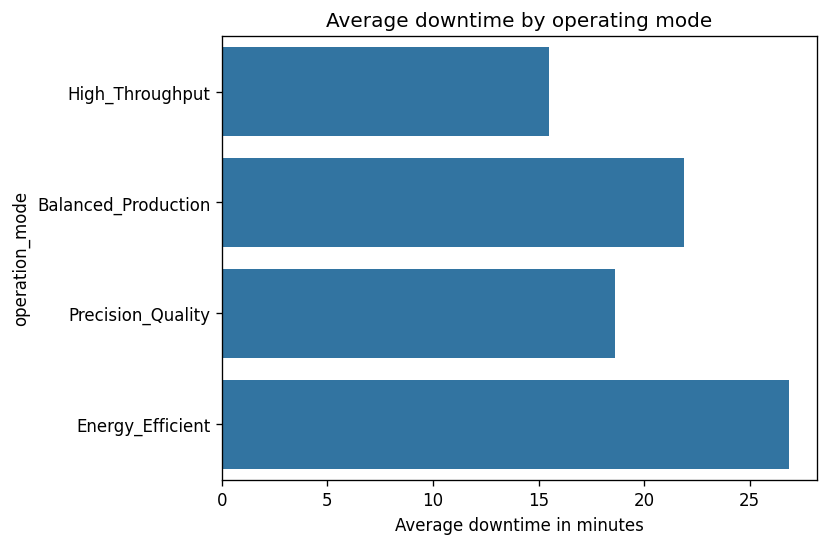

In [11]:
sns.barplot(data=df, x='downtime_minutes', y='operation_mode', errorbar=None)
plt.title('Average downtime by operating mode')
plt.xlabel('Average downtime in minutes')
plt.show()


## Downtime by shift

In [12]:
df.groupby('shift')['downtime_minutes'].agg(['count', 'mean', 'median'])


,count,mean,median
shift,,,
Afternoon,5681,21.170171,20.758800
Morning,6039,21.287642,20.953838
Night,3280,21.120030,20.731123


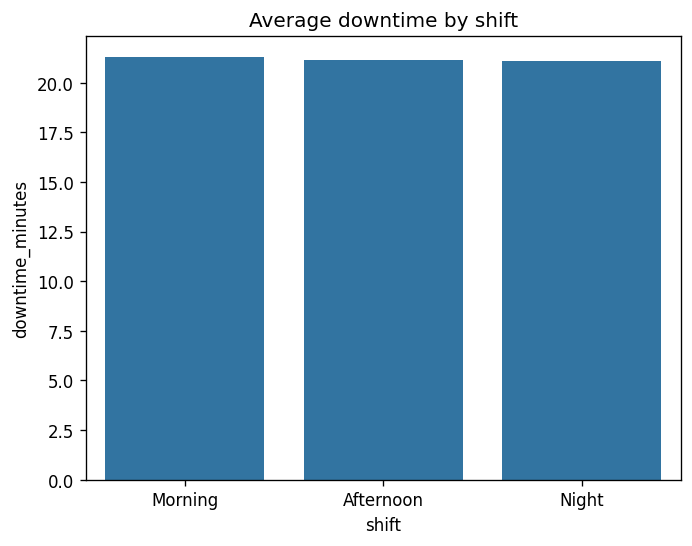

In [13]:
sns.barplot(data=df, x='shift', y='downtime_minutes', errorbar=None)
plt.title('Average downtime by shift')
plt.show()


## Downtime by production line

In [14]:
df.groupby('production_line')['downtime_minutes'].agg(['count', 'mean']).sort_values('mean', ascending=False)


,count,mean
production_line,,
Line_A,2982,21.404648
Line_D,3024,21.258833
Line_C,2947,21.205407
Line_E,3083,21.093420
Line_B,2964,21.072466


## Downtime by machine
Check the record count as well as the average. Actual operating hours are not supplied.

In [15]:
df.groupby('machine_id')['downtime_minutes'].agg(['count', 'mean']).sort_values('mean', ascending=False)


,count,mean
machine_id,,
M13,816,21.708855
M12,766,21.675205
M01,729,21.574469
M10,743,21.487916
M18,754,21.484048
M09,722,21.369983
M04,751,21.353614
M03,745,21.349689
M15,798,21.267185


## Downtime by product type

In [16]:
df.groupby('product_type')['downtime_minutes'].agg(['count', 'mean', 'median'])


,count,mean,median
product_type,,,
Product_A,4464,21.056726,20.612294
Product_B,4224,21.256151,20.937944
Product_C,3645,21.213243,20.917340
Product_D,2667,21.369340,21.007628


## Vibration distribution
These charts include the filled sensor readings. Filling with one value can create a spike in a distribution.

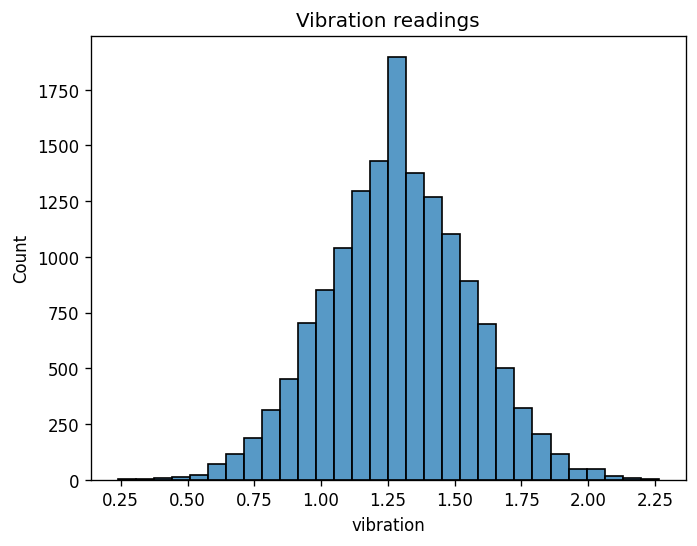

In [17]:
sns.histplot(data=df, x='vibration', bins=30)
plt.title('Vibration readings')
plt.show()


## Motor temperature distribution

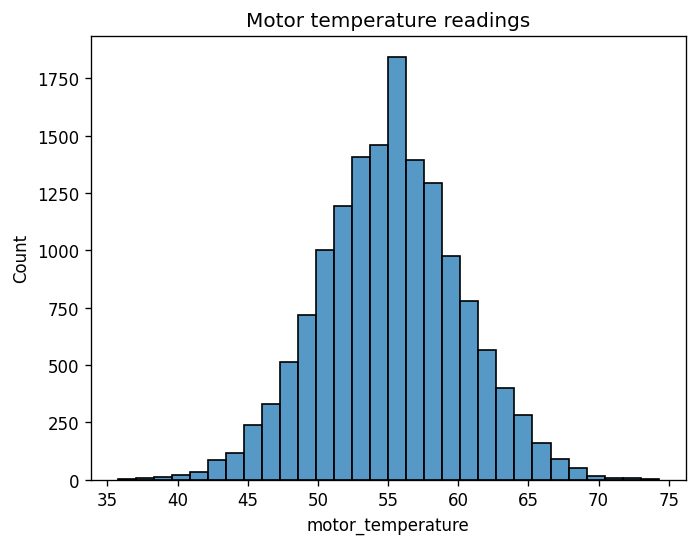

In [18]:
sns.histplot(data=df, x='motor_temperature', bins=30)
plt.title('Motor temperature readings')
plt.show()


## Correlation with downtime
Positive: values tend to increase together. Negative: one tends to decrease as the other increases. Correlation does not prove cause.

In [19]:
numeric = df.select_dtypes(include='number').drop(columns='record_id')
correlations = numeric.corr()['downtime_minutes'].drop('downtime_minutes')
correlations.sort_values(ascending=False)


,downtime_minutes
fault_event_count,0.782579
maintenance_frequency,0.629859
production_cost_per_unit,0.456741
vibration,0.247312
motor_temperature,0.068212
bearing_temperature,0.064054
defect_rate,0.048626
acoustic_level,0.025342
power_consumption,0.018216
air_pressure,0.018163


## Vibration and downtime

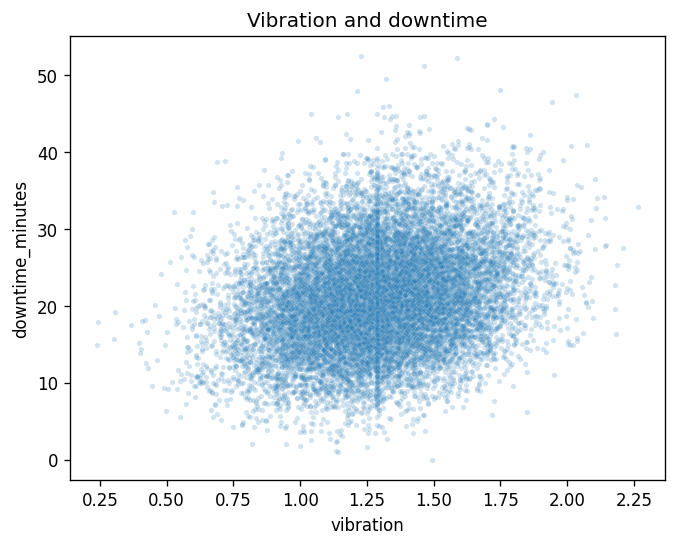

In [20]:
sns.scatterplot(data=df, x='vibration', y='downtime_minutes', alpha=0.2, s=10)
plt.title('Vibration and downtime')
plt.show()


## Fault count and downtime
Fault count can explain recorded downtime, but check whether it was known before prediction before using it as a model input.

In [21]:
df.groupby('fault_event_count')['downtime_minutes'].agg(['count', 'mean'])


,count,mean
fault_event_count,,
0,1832,13.391899
1,3723,17.268400
2,4070,20.684468
3,2891,24.352585
4,1527,28.046443
5,640,31.774863
6,223,35.086861
7,70,37.953773
8,21,42.112602


## Check the classification target
Only one record has zero downtime, so using “any downtime” would put almost every record in one class.

In [22]:
print('Zero downtime:', (df['downtime_minutes'] == 0).sum())
print('Positive downtime:', (df['downtime_minutes'] > 0).sum())


Zero downtime: 1
Positive downtime: 14999


## Example high-downtime definition
30 minutes is an example threshold, not an original label. Agree on the threshold before training the models.

In [23]:
threshold = 30
high_downtime = df['downtime_minutes'] >= threshold
print('High-downtime records:', high_downtime.sum())
print('High-downtime percentage:', round(high_downtime.mean() * 100, 2))


High-downtime records: 1502
High-downtime percentage: 10.01


## Save operating-mode summary

In [24]:
mode_summary = df.groupby('operation_mode')['downtime_minutes'].agg(['count', 'mean', 'median'])
mode_summary.to_csv('downtime_by_mode.csv')


## Save machine summary

In [25]:
machine_summary = df.groupby('machine_id')['downtime_minutes'].agg(['count', 'mean', 'median'])
machine_summary.to_csv('downtime_by_machine.csv')


## Main findings
- Mean downtime is about 21.21 minutes; the median is about 20.84.
- Operating-mode means differ more than shift and production-line means.
- Fault count, maintenance frequency and vibration are associated with recorded downtime.
- The example ≥30-minute label gives about 10% positive records; accuracy alone is not enough to compare the models.




## Business findings and insights
The findings below come from the existing EDA outputs in this notebook. Suggested actions are investigation priorities, not proven causes or guaranteed improvements.

| Finding | Business meaning | Suggested action |
|---|---|---|
| Average downtime is **21.21 minutes per record**; the median is **20.84 minutes**. | This describes typical recorded stoppage duration and provides a baseline for comparison. | Monitor mean, median and long stoppages when evaluating future improvements. |
| Records with **0 faults** average **13.39 minutes** of downtime; records with **5 faults** average **31.77 minutes**. | More recorded machine problems are associated with longer stoppages. | Review recurring faults and repair logs to identify maintenance priorities. Confirm when faults were recorded before using them for prediction. |
| **Energy_Efficient** mode averages **26.86 minutes**, compared with **15.48 minutes** for **High_Throughput**. | Operating modes show an observed **11.38-minute difference** in mean downtime. | Compare workload, energy use and product quality across modes before recommending an operating change. The gap is not guaranteed savings from switching modes. |
| Shift means range from **21.12 to 21.29 minutes**. Production-line means range from **21.07 to 21.40 minutes**. | Shift and line differences are small compared with operating-mode differences. | Give fault patterns and operating conditions more attention initially, while continuing to monitor shifts and lines. |
| Machine means range from **20.60 minutes for M20** to **21.71 minutes for M13**. | There is some variation, but the difference alone does not establish which machine is least reliable. | Review workload, operating hours and maintenance history before prioritizing machine replacement or major repairs. |
| Vibration has a positive correlation of about **0.25** with downtime. | Higher measured shaking sometimes accompanies longer stoppages, but vibration alone explains only part of the pattern. | Consider vibration alongside other available sensor readings. Do not set an unsafe-vibration threshold without sensor units and operating limits. |
| Production cost per unit has a positive correlation of about **0.46** with downtime. | Longer stoppages are associated with higher unit costs in this file. | Investigate stoppage-related costs and collect verified financial information before estimating savings or maintenance payback. |


## Business conclusion
The analysis suggests that **recurring faults and operating-mode differences deserve further investigation**. Differences between shifts and production lines are comparatively small. Vibration may provide supporting information, while the relationship between downtime and unit cost highlights the business importance of understanding stoppages.

### Interpretation limits
These results show **associations**, not proof of causes or guaranteed savings. The averages are **minutes per record**, not exposure-adjusted failure rates. The observation window and actual operating hours are not documented, so summed downtime should not be presented as verified factory hours lost. Some sensor values were filled during cleaning; these estimates can affect distributions and correlations. No financial currency or validated cost-per-minute figure was supplied.
